# 30. The final experiment: which scene fits?

[Course plan](../../README.md)

There is a sculpture, room for 2200 bytes and a viewer drawing at 80 × 60. The largest packet will not fit. The smallest one will, but it may lose color. A short list of measurements, a selection rule and a settings file make the choice repeatable.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "en"

## Two photographs with different jobs

First we fix the details that can silently change the outcome. One original model of 117 splats, a white background, the same cameras, an 80 × 60 image and one renderer version. All four packets render `view-00.jpg`. This view helped fit the original sculpture. Here it serves as a calibration image for selecting a compression method. The photograph `view-04.jpg` was held out during training. Its score appears only after the choice. Repeatedly tuning thresholds against that held-out image would call for a fresh camera view for the next independent check.

There are $80\cdot60\cdot3=14400$ channel values. For each one we subtract the target from the prediction, square, sum the differences and divide by 14400. If red is 0.7 instead of 0.6, its contribution is $(0.7-0.6)^2=0.01$. Normalized RGB has a peak channel value of 1. PSNR in decibels is then $10\log_{10}(1/\mathrm{MSE})$. For a mean squared error of 0.01 the ratio is 100. Since $10^2=100$, the logarithm is 2 and the score is 20 dB. Exact agreement gives zero MSE and infinite PSNR.

In [2]:
settings_path = course / 'data' / 'codec-study' / 'settings.json'
cfg = json.loads(settings_path.read_text(encoding='utf8'))
report = codec.benchmark_photo(cfg)
for r in report['candidates']:
    print(f"{r['name']:14} {r['bytes']:5} B   {r['validationPsnr']:.3f} dB   "
          f"decode {r['decodeMs']:.3f} ms   frame {r['renderMs']:.3f} ms")
print(report['selected'], report['test'])

f32-rgb         6560 B   20.244 dB   decode 0.083 ms   frame 52.650 ms
u8-rgb          1694 B   20.271 dB   decode 0.178 ms   frame 52.786 ms
u8-half          882 B   19.272 dB   decode 0.083 ms   frame 52.004 ms
u8-gray-half     764 B   19.191 dB   decode 0.142 ms   frame 32.645 ms
u8-rgb {'view': 'view-04.jpg', 'mse': 0.00983929764663813, 'psnr': 20.07035901474754}


## How four rows become one

| Packet | Contents | Bytes | PSNR on view-00 |
|---|---|---:|---:|
| f32-rgb | 117 float32 splats | 6560 | 20.24 dB |
| u8-rgb | The same 117 in uint8 | 1694 | 20.27 dB |
| u8-half | 59 color splats | 882 | 19.27 dB |
| u8-gray-half | 59 gray splats | 764 | 19.19 dB |

Here PSNR compares each variant **with the photograph**. Rounding can slightly improve an individual pixel in an imperfect original fit. A 0.03 dB difference on one camera says little about the rest of the scene.

The rule is fixed before the comparison. Size must be at most 2200 bytes and quality on the calibration view at least 16 dB. The first packet fails because $6560>2200$. Three remaining packets pass both thresholds. With quality as the priority, `u8-rgb` wins at 20.27 dB. The float32 file would transmit $6560/1694\approx3.87$ times as many bytes. Now the held-out photograph comes into play. Its MSE is about 0.009839, giving $10\log_{10}(1/0.009839)\approx20.07$ dB. Prioritizing size instead would select the 764-byte grayscale packet.

In [3]:
display(demos.codec_lab(30, lang))

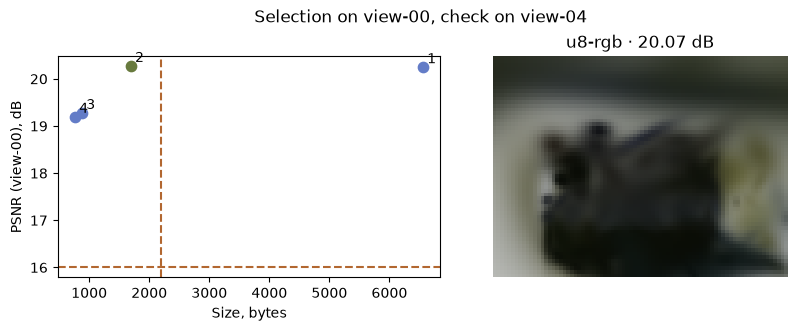

In [4]:
demos.study_figure(report, lang)
plt.show()

## Time, memory and the device

Decoding is paid once when the packet opens. Rendering is paid for each new frame. If decoding took 1 ms and each frame took 25 ms, then 40 frames would cost $1+40\cdot25=1001$ ms before network transfer. At 30 frames per second the budget is $1000/30\approx33.3$ ms per frame, including the rest of the application. The latency priority selects the eligible packet with the lowest median render time. Transfer and decode time are separate costs.

A warm-up removes some startup effects. Three measurements of 22, 24 and 61 ms would give a median of 24 ms, the middle observation in sorted order. NumPy on the CPU and JavaScript in a browser are different implementations. The browser times batches of short calls. A float64 RGB output occupies $80\cdot60\cdot3\cdot8=115200$ bytes. That count covers the output array alone. It cannot establish peak process or GPU memory. The [saved report](../../data/codec-study/reference.json) records the operating system, architecture and library versions alongside its measured times. Timing deserves a fresh run on another device.

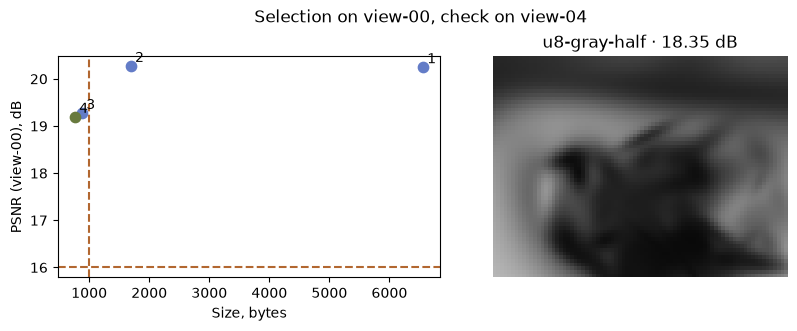

80 × 60 × 3 × 8 = 115200 bytes


In [5]:
demos.study_figure(report, lang, max_bytes=1000, min_psnr=16, priority='size')
plt.show()
print('80 × 60 × 3 × 8 =', report['candidates'][0]['bufferBytes'], 'bytes')

## What changes for motion?

The sculpture only needs one set of centers. The ribbon from lesson 26 moves. A fair comparison starts with the same canonical packet and adds each motion stream to it. Here that common packet includes the starting centers. Frame rate and clip duration are known to both sides. Transport headers are outside the count.

Suppose there are 500 extra bytes for motion. With five splats, 17 dense frames need 1036 bytes and fail the limit. Anchors every eight frames take 196 bytes, or 406 with residuals. Quality between anchors now matters. The cell uses times 0.19, 0.37 and 0.71 s, none present on the recorded grid. Two cameras see the same motion. First we average the MSE of the six equally sized images and then convert that average error to decibels. This measures compression error against the fitted movement from lesson 26. The sculpture photographs play no part in this comparison.

In [6]:
from deformation import scene_at
model, xyz = codec.motion_data()
base = len(codec.pack_static(model['canonical'], 'f32'))
for mode in ['dense', 'keys', 'residual']:
    packet = codec.pack_motion(xyz, mode, stride=8, quantum=.002)
    track = codec.unpack_motion(packet)
    errors = []
    for t in [.19, .37, .71]:
        decoded = codec.pose_with_centers(model['canonical'], codec.sample_track(track, t))
        for angle in [-25, 32]:
            camera = orbit_camera(angle, 55)
            image = render_scene(decoded, camera, 65, 49)
            target = render_scene(scene_at(model, t), camera, 65, 49)
            errors.append(scores(image, target)['mse'])
    print(mode, 'motion B:', len(packet), 'total B:', base+len(packet),
          'PSNR dB:', round(-10*np.log10(np.mean(errors)), 2),
          'decode ms:', round(benchmark(lambda: codec.unpack_motion(packet)), 4))

dense motion B: 1036 total B: 1324 PSNR dB: 69.49 decode ms: 0.0045
keys motion B: 196 total B: 484 PSNR dB: 29.52 decode ms: 0.0832
residual motion B: 406 total B: 694 PSNR dB: 69.36 decode ms: 0.1041


## A file for the next run

The [experiment settings](../../data/codec-study/settings.json) hold the limits, priority, resolution and repetition count. The Download settings button writes the current values to the same JSON format. The saved file can be opened again in the experiment. From the repository root, the [benchmark script](../../scripts/benchmark_codecs.py) reads this file and writes a new report:

```sh
python scripts/benchmark_codecs.py --settings data/codec-study/settings.json --output codec-report.json
```

Byte counts and images follow from the source data and rounding rules. Time is measured on the running machine. Two computers with identical settings can therefore choose different packets when speed has priority.

**Experiment.** Which packet survives a 900-byte limit and a 19.25 dB floor? What changes if the floor rises to 19.5 dB?

<details>
<summary>Worked answer</summary>

Two packets fit within 900 bytes. The color packet reaches about 19.27 dB and clears 19.25. The gray packet at 19.19 dB falls short. At 19.5 dB all four candidates fail at least one constraint. A larger byte budget or an intermediate retention setting from lesson 28 would open up another experiment.

</details>